---
title: "Chapter 19 demo: Rain in Australia"
sidebar: demos
---

This walkthrough uses Rain in Australia to practise a workflow you can adapt to HW8: identify separate time series, inspect their spacing, understand a future target, establish a persistence baseline, and compare calendar and lag features.

We keep a classification task: predict whether it will rain tomorrow. In HW8, you will adapt these ideas to regression and a weekly forecast horizon.

Run the cells in order. Download the dataset from [here](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package) and place `weatherAUS.csv` in a `data` folder beside this notebook.

In [1]:
#| code-fold: true
#| code-summary: "Show imports and setup"
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_DIR = Path("data") if Path("data").is_dir() else Path("book") / "data"

## Define the prediction task

At the end of each measurement day, predict `RainTomorrow` at the same location. We assume that day's listed measurements are available at this time. In deployment, publication delays and the exact observation windows would need checking.

The target is categorical, so we use classification. We predict one day at a time: measurements arrive between predictions, while the fitted model stays fixed during each validation period. This is different from predicting an entire month's rain at its beginning.

In [2]:
rain = pd.read_csv(DATA_DIR / "weatherAUS.csv", parse_dates=["Date"])
rain = rain.sort_values(["Location", "Date"]).reset_index(drop=True)
assert not rain.duplicated(["Location", "Date"]).any()
display(rain.head())
print("Locations:", rain["Location"].nunique())
print("Date range:", rain["Date"].min(), "to", rain["Date"].max())
display(rain.isna().mean().sort_values(ascending=False).head(8))

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-07-02,Adelaide,12.7,15.8,0.8,1.4,7.8,SW,35.0,SSW,...,52.0,1022.4,1022.6,NaN,NaN,13.7,15.5,No,0.0,No
1,2008-07-03,Adelaide,6.2,15.1,0.0,1.8,2.1,W,20.0,NNE,...,56.0,1027.8,1026.5,NaN,NaN,9.3,13.9,No,0.0,No
2,2008-07-04,Adelaide,5.3,15.9,0.0,1.4,8.0,NNE,30.0,NNE,...,46.0,1028.7,1025.6,NaN,NaN,10.2,15.3,No,0.0,No
3,2008-07-05,Adelaide,9.8,15.4,0.0,NaN,0.9,N,30.0,NNE,...,67.0,1023.6,1020.2,NaN,NaN,11.3,13.8,No,NaN,NaN
4,2008-07-06,Adelaide,11.3,15.7,NaN,NaN,1.5,NNW,52.0,NNE,...,62.0,1019.5,1016.2,NaN,NaN,13.0,14.4,NaN,16.2,Yes


Locations: 46
Date range: 2007-11-01 00:00:00 to 2012-01-30 00:00:00


Sunshine         0.367777
Cloud3pm         0.351997
Evaporation      0.348309
Cloud9am         0.338928
Pressure9am      0.096852
Pressure3pm      0.096310
WindGustDir      0.091321
WindGustSpeed    0.091131
dtype: float64

## Identify the separate time series

Several locations can have observations on the same date. Inspect repeated dates, then check whether `(Location, Date)` uniquely identifies an observation. In another dataset, you may need a combination of categorical columns to identify each series.

In [3]:
first_date = rain["Date"].value_counts().idxmax()
display(rain.loc[rain["Date"].eq(first_date), ["Date", "Location", "Rainfall"]].head(10))
series_summary = rain.groupby("Location").agg(
    rows=("Date", "size"), unique_dates=("Date", "nunique"),
    first_date=("Date", "min"), last_date=("Date", "max"))
display(series_summary.head())
assert series_summary["rows"].eq(series_summary["unique_dates"]).all()

,Date,Location,Rainfall
180,2009-03-03,Adelaide,1.6
948,2009-03-03,Albany,0.4
1756,2009-03-03,Albury,0.0
2550,2009-03-03,AliceSprings,0.0
3323,2009-03-03,BadgerysCreek,0.0
4131,2009-03-03,Ballarat,0.8
4951,2009-03-03,Bendigo,3.2
5851,2009-03-03,Brisbane,0.2
6635,2009-03-03,Cairns,0.0
7722,2009-03-03,Canberra,0.0


,rows,unique_dates,first_date,last_date
Location,,,,
Adelaide,887,887,2008-07-02,2012-01-28
Albany,802,802,2008-12-01,2012-01-30
Albury,795,795,2008-12-01,2012-01-29
AliceSprings,792,792,2008-12-02,2012-01-30
BadgerysCreek,788,788,2009-01-01,2012-01-27


A series identifier does not establish that observations are independent or that geographic categories do not overlap. Nearby weather stations can share weather patterns. In other datasets, labels can mix cities, larger regions, and national totals.

**Pause:** What evidence would you inspect before adding measurements across geographic labels? Look at the labels and any dataset documentation; where meaningful, compare candidate totals with their components.

## Inspect spacing within each series

Sort within each location before taking date differences. A difference across the whole dataframe could cross a location boundary.

Date
1 days     25757
2 days      7709
3 days      2349
4 days       685
5 days       216
6 days        50
7 days        15
8 days         2
9 days         3
10 days        2
11 days        1
31 days       24
32 days        9
33 days        8
34 days        3
35 days        1
37 days        1
Name: Number of gaps, dtype: int64

,min,max
Location,,
Hobart,1 days,37 days
Wollongong,1 days,35 days
Portland,1 days,34 days
Bendigo,1 days,34 days
Cobar,1 days,34 days
PerthAirport,1 days,33 days
BadgerysCreek,1 days,33 days
Penrith,1 days,33 days
Nuriootpa,1 days,33 days


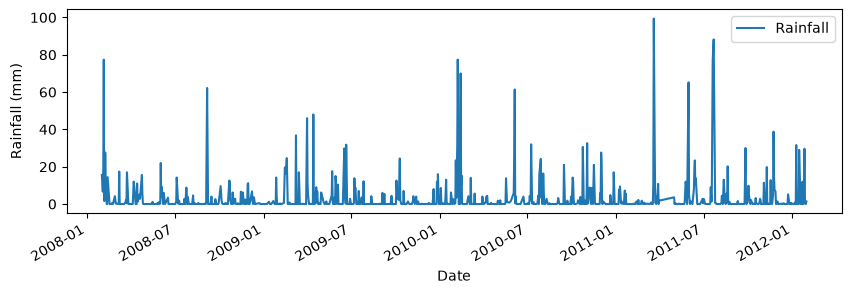

In [4]:
spacing = rain.groupby("Location")["Date"].diff()
display(spacing.value_counts().sort_index().rename("Number of gaps"))
gap_summary = rain.assign(gap=spacing).groupby("Location")["gap"].agg(["min", "max"])
display(gap_summary.sort_values("max", ascending=False).head(10))
sydney = rain.loc[rain["Location"].eq("Sydney")]
sydney.plot(x="Date", y="Rainfall", figsize=(10, 3), ylabel="Rainfall (mm)")
plt.show()

## Understand shifts and the future target

The file supplies `RainTomorrow`. To understand how a future target can be constructed, take the next row's `RainToday` **within the same location**. Also shift its date so we can check the forecast horizon.

Pandas uses `shift(1)` for the previous observation and `shift(-1)` for the next observation. HW8's `create_lag_feature` helper uses the opposite sign convention in its `lag` argument: **negative = past, positive = future**. Inspect the helper rather than assuming its signs match pandas.

A future value can define a target; it must not enter the predictors.

In [5]:
shift_example = rain[["Location", "Date", "RainToday", "RainTomorrow"]].copy()
by_location = rain.groupby("Location", sort=False)
shift_example["PreviousRainToday"] = by_location["RainToday"].shift(1)
shift_example["NextRainToday"] = by_location["RainToday"].shift(-1)
shift_example["NextDate"] = by_location["Date"].shift(-1)
is_next_day = shift_example["NextDate"].sub(shift_example["Date"]).eq(np.timedelta64(1, "D"))
shift_example["ConstructedRainTomorrow"] = shift_example["NextRainToday"].where(is_next_day)
display(shift_example.loc[shift_example["Location"].eq("Sydney")].head(8))
comparable = shift_example.loc[
    is_next_day & shift_example["RainTomorrow"].notna()
    & shift_example["ConstructedRainTomorrow"].notna()]
print("Comparable next-day observations:", len(comparable))
print("Agreement with supplied target:",
      comparable["RainTomorrow"].eq(comparable["ConstructedRainTomorrow"]).mean())
display(shift_example.loc[shift_example["NextDate"].notna() & ~is_next_day].head())

,Location,Date,RainToday,RainTomorrow,PreviousRainToday,NextRainToday,NextDate,ConstructedRainTomorrow
28195,Sydney,2008-02-01,Yes,Yes,NaN,Yes,2008-02-03,NaN
28196,Sydney,2008-02-03,Yes,Yes,Yes,Yes,2008-02-04,Yes
28197,Sydney,2008-02-04,Yes,Yes,Yes,Yes,2008-02-05,Yes
28198,Sydney,2008-02-05,Yes,Yes,Yes,Yes,2008-02-06,Yes
28199,Sydney,2008-02-06,Yes,Yes,Yes,Yes,2008-02-07,Yes
28200,Sydney,2008-02-07,Yes,Yes,Yes,Yes,2008-02-08,Yes
28201,Sydney,2008-02-08,Yes,Yes,Yes,Yes,2008-02-09,Yes
28202,Sydney,2008-02-09,Yes,Yes,Yes,Yes,2008-02-10,Yes


Comparable next-day observations: 25324
Agreement with supplied target: 1.0


,Location,Date,RainToday,RainTomorrow,PreviousRainToday,NextRainToday,NextDate,ConstructedRainTomorrow
8,Adelaide,2008-07-10,Yes,No,Yes,NaN,2008-07-12,NaN
11,Adelaide,2008-07-14,Yes,Yes,NaN,No,2008-07-16,NaN
14,Adelaide,2008-07-18,Yes,NaN,No,Yes,2008-07-21,NaN
17,Adelaide,2008-07-23,No,No,No,No,2008-07-25,NaN
18,Adelaide,2008-07-25,No,NaN,No,No,2008-07-28,NaN


The date check prevents calling a later observation “tomorrow” when days are missing. Any disagreement with the supplied target warrants investigating the dataset's definitions and missing-value handling. This is an illustration only: we retain the supplied `RainTomorrow` for modeling and keep these demonstration columns out of the model data.

A previous observation is not always yesterday's observation. We will construct yesterday's measurement by matching the exact date and location. We do this before removing missing targets: a row without a target can still contain an observed measurement useful for the next day's prediction.

In [6]:
yesterday = rain[["Location", "Date", "Rainfall", "Humidity3pm"]].copy()
yesterday["Date"] = yesterday["Date"] + pd.Timedelta(1, unit="D")
yesterday = yesterday.rename(columns={
    "Rainfall": "Rainfall_lag1day", "Humidity3pm": "Humidity3pm_lag1day"
})
rain = rain.merge(yesterday, on=["Location", "Date"], how="left", validate="one_to_one")
rain["MonthNumeric"] = rain["Date"].dt.month
rain["Month"] = rain["Date"].dt.month_name()
rain = rain.dropna(subset=["RainTomorrow"]).copy()
display(rain[["Location", "Date", "Rainfall", "Rainfall_lag1day"]].head(10))

,Location,Date,Rainfall,Rainfall_lag1day
0,Adelaide,2008-07-02,0.8,NaN
1,Adelaide,2008-07-03,0.0,0.8
2,Adelaide,2008-07-04,0.0,0.0
4,Adelaide,2008-07-06,NaN,0.0
5,Adelaide,2008-07-07,16.2,NaN
6,Adelaide,2008-07-08,17.0,16.2
7,Adelaide,2008-07-09,1.8,17.0
8,Adelaide,2008-07-10,9.0,1.8
10,Adelaide,2008-07-13,NaN,NaN
11,Adelaide,2008-07-14,3.8,NaN


The merge uses only past measurements. If yesterday is missing, the lag remains missing; it does not silently substitute a measurement from several days ago. We will impute missing predictors inside each training fold.

## Establish a holdout and validation folds

Use the first 80% of observed dates for development and the remaining dates for a final holdout. This adapts to the date range in the local CSV. How would ordinary `TimeSeriesSplit` behave if several rows share the same date?

Splitting rows can place different locations from the same date on opposite sides of a boundary. Instead, split unique dates, then map each date window back to rows. All locations on a date stay together. This evaluates future predictions at the locations represented in our data; it does not evaluate transfer to unseen locations.

In [7]:
#| code-fold: true
#| code-summary: "Show chronological holdout and date-based validation folds"
all_dates = np.sort(rain["Date"].unique())
cutoff = pd.Timestamp(all_dates[int(0.8 * len(all_dates)) - 1])
train = rain.loc[rain["Date"] <= cutoff].sort_values(["Date", "Location"]).reset_index(drop=True)
test = rain.loc[rain["Date"] > cutoff].sort_values(["Date", "Location"]).reset_index(drop=True)
# Apply the target-availability gap before constructing positional fold indices.
train = train.loc[train["Date"] < test["Date"].min() - pd.Timedelta(1, unit="D")].reset_index(drop=True)
assert not train.empty and not test.empty
y_train, y_test = train["RainTomorrow"], test["RainTomorrow"]
dates = np.sort(train["Date"].unique())
folds = []
for fit_dates, valid_dates in TimeSeriesSplit(n_splits=3).split(dates):
    fit_rows = np.flatnonzero(train["Date"].isin(dates[fit_dates]))
    valid_rows = np.flatnonzero(train["Date"].isin(dates[valid_dates]))
    # RainTomorrow for date d is not known until the following day.
    # Leave a day between the last training feature date and validation origin.
    first_validation_date = train.iloc[valid_rows]["Date"].min()
    fit_rows = fit_rows[(train.iloc[fit_rows]["Date"] < first_validation_date - pd.Timedelta(1, unit="D")).to_numpy()]
    assert len(fit_rows) > 0 and len(valid_rows) > 0
    assert train.iloc[fit_rows]["Date"].max() < first_validation_date - pd.Timedelta(1, unit="D")
    folds.append((fit_rows, valid_rows))
    print(train.iloc[fit_rows]["Date"].max().date(), "→", first_validation_date.date())

2008-10-08 → 2008-10-10
2009-07-29 → 2009-07-31
2010-05-19 → 2010-05-21


The extra gap conservatively allows the next day's outcome to become available before fitting. The exact gap should reflect the observation and publication schedule in the real application.

## Establish two baselines

A majority baseline always predicts the most frequent training class. A **persistence baseline** predicts tomorrow's rain using today's `RainToday`. If today's value is missing, we use the most frequent training value.

For a numeric target, persistence means predicting the next value with the current value, then evaluating with a regression metric such as `r2_score(y_next, y_current)`. Here we use classification metrics: accuracy and balanced accuracy. Balanced accuracy averages recall across the classes and helps reveal how a majority baseline performs on an imbalanced target.

In [8]:
class PersistenceClassifier(ClassifierMixin, BaseEstimator):
    """Predict tomorrow's class using today's observed class."""
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.fill_value_ = X["RainToday"].mode().iloc[0]
        return self

    def predict(self, X):
        return X["RainToday"].fillna(self.fill_value_).to_numpy()

baselines = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Persistence baseline": PersistenceClassifier(),
}
results = {}
for name, model in baselines.items():
    results[name] = cross_val_score(
        model, train[["RainToday"]], y_train, cv=folds, scoring="balanced_accuracy")
display(pd.DataFrame(results, index=["Fold 1", "Fold 2", "Fold 3"]).T)

,Fold 1,Fold 2,Fold 3
Majority baseline,0.500000,0.500000,0.500000
Persistence baseline,0.684743,0.659733,0.650066


## Compare calendar encodings and historical features

Keep the classifier and validation folds fixed while changing the features:

1. Current measurements only.
2. Current measurements plus numeric month.
3. Current measurements plus one-hot month.
4. Current measurements plus one-hot month and yesterday's measurements.

For logistic regression, numeric month contributes a linear term to the log odds: moving from January to February has the same modeled increment as moving from November to December. It also fails to represent December and January as neighbors in a seasonal cycle. One-hot encoding lets each month have a separate effect. The same limitation applies to numeric time of day in a linear regression model. Sine/cosine encoding is another possible approach, beyond this comparison.

The `ColumnTransformer` below selects predictors explicitly. The target and any other columns are excluded; in particular, if the local CSV includes `RISK_MM` (next-day rainfall), it must never be a predictor.

In [9]:
numeric = [
    "MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine",
    "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm", "Humidity9am",
    "Humidity3pm", "Pressure9am", "Pressure3pm", "Cloud9am", "Cloud3pm",
    "Temp9am", "Temp3pm",
]
categorical = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]

def make_rain_model(extra_numeric=(), extra_categorical=()):
    preprocessing = ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
         numeric + list(extra_numeric)),
        ("categorical", make_pipeline(
            SimpleImputer(strategy="constant", fill_value="missing"),
            OneHotEncoder(handle_unknown="ignore")),
         categorical + list(extra_categorical)),
    ])
    return make_pipeline(preprocessing, LogisticRegression(max_iter=1000))

models = {
    **baselines,
    "Measurements": make_rain_model(),
    "Measurements + numeric month": make_rain_model(extra_numeric=["MonthNumeric"]),
    "Measurements + month": make_rain_model(extra_categorical=["Month"]),
    "Measurements + month + lags": make_rain_model(
        extra_numeric=["Rainfall_lag1day", "Humidity3pm_lag1day"],
        extra_categorical=["Month"]),
}
for name, model in models.items():
    if name in baselines:
        continue
    X = train
    results[name] = cross_val_score(
        model, X, y_train, cv=folds, scoring="balanced_accuracy"
    )
validation = pd.DataFrame(results, index=["Fold 1", "Fold 2", "Fold 3"]).T
validation["Mean"] = validation.mean(axis=1)
display(validation)

,Fold 1,Fold 2,Fold 3,Mean
Majority baseline,0.500000,0.500000,0.500000,0.500000
Persistence baseline,0.684743,0.659733,0.650066,0.664847
Measurements,0.708412,0.721213,0.738322,0.722649
Measurements + numeric month,0.699834,0.726957,0.741160,0.722650
Measurements + month,0.706047,0.720391,0.744117,0.723518
Measurements + month + lags,0.702681,0.720770,0.744688,0.722713


## Interpret the feature comparisons

Month is known in advance and may capture seasonal differences. We encode it categorically rather than imposing a linear increase from January to December. Location lets one model use data across stations, although this additive logistic model does not automatically learn location-specific seasonal effects.

Lag features provide yesterday's measurements, while today's rainfall and humidity are already present. The lags may add little once current measurements are included. Their usefulness is an empirical question, not a guarantee.

::: {.callout-note}
### Pause and discuss

- Do the feature additions improve every validation fold, or only the average?
- Would yesterday's observed humidity remain available if we forecast an entire month in advance?
- Why would grouping by location before `shift(1)` still be insufficient to guarantee a one-day lag?

Grouping prevents crossing locations, but only a date check or an exact date match establishes the elapsed interval. Observed future-period measurements are available in this repeated one-day setup, not for a whole month forecast at once.
:::

### History at the train/test boundary

We created historical predictors before splitting. That lets the first test date use an earlier observed measurement from the training period. It also lets later test dates use measurements that have arrived since the test period began, consistent with our repeated one-day prediction task.

Creating lags separately within train and test would discard available history at the boundary. Using future measurements would leak information. Imputation, scaling, and model fitting remain inside the pipeline and use only each fold's training rows.

## Evaluate the selected approach

Select using validation balanced accuracy, then inspect the final holdout once. Small validation differences may be unstable; simplicity and consistency across periods matter too.

In [10]:
best_name = validation["Mean"].idxmax()
selected = models[best_name]
X_train = train[["RainToday"]] if best_name in baselines else train
X_test = test[["RainToday"]] if best_name in baselines else test
selected.fit(X_train, y_train)
predictions = selected.predict(X_test)
print("Selected:", best_name)
print(f"Holdout accuracy: {accuracy_score(y_test, predictions):.3f}")
print(f"Holdout balanced accuracy: {balanced_accuracy_score(y_test, predictions):.3f}")

Selected: Measurements + month
Holdout accuracy: 0.838
Holdout balanced accuracy: 0.731


This estimate describes future dates at the observed locations under our information-availability assumptions. A different forecast horizon, a new location, or a change in measurement practices would require a different evaluation design.

The main adaptations were to define the prediction timing, split by dates, account for target availability, and match lag measurements within location by elapsed time. The classification pipeline itself remained familiar.

## Transfer this workflow to HW8

Before modeling a new time-series dataset, explain:

- **Series:** Which column or combination of columns identifies one sequence? Can geographic labels overlap?
- **Spacing:** Are dates unique and equally spaced within each sequence? What does one row shift mean?
- **Task:** What is the forecast horizon, how is the future target constructed, and which measurements are available when predicting?
- **Baseline:** What does “the next value equals the current value” predict? Which metric fits the target type?
- **Features:** How will you compare date encodings and past measurements using the same evaluation periods?
- **Evaluation:** Do training dates precede validation dates, are training targets available at fitting time, and is the final holdout reserved for the selected approach?

A useful feature need not improve every dataset. Report the comparisons and justify the choices using evidence.